In [1]:
import sys
sys.path.append('Scripts/')

import tensorflow as tf

from SyntheticHouseholds import *
from simulation import *
from SMC2 import *

2026-10-20 18:00:21.036257: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 18:00:21.049639: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792512021.061915   64760 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792512021.065609   64760 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-20 18:00:21.079082: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
import os
os.getcwd()

'/home/rimella/PythonDirectory/RTT/SMC2-ILM/Tutorial'

In [3]:
import numpy as np

########################################################
# Load the data
########################################################
n_individuals_chikwawa          = np.load("Data/Input/n_individuals_chikwawa.npy")
n_households_chikwawa           = np.load("Data/Input/n_households_chikwawa.npy")
households_longitude_chikwawa   = np.load("Data/Input/households_longitude_chikwawa.npy")
households_latitude_chikwawa    = np.load("Data/Input/households_latitude_chikwawa.npy")
loc_H_I_index_chikwawa          = np.load("Data/Input/loc_H_I_index_chikwawa.npy")
individuals_covariates_chikwawa = np.load("Data/Input/individuals_covariates_chikwawa.npy")

Y_klebs_chikwawa = np.load("Data/Input/Y_kpneu_chikwawa.npy")

hyperparameters_epidemic = {}
hyperparameters_epidemic["initial_colonize_prob"] = 0.13
hyperparameters_epidemic["gamma"]                 = 1/10
hyperparameters_epidemic["coef"]                  = 0.8
hyperparameters_epidemic["individual_coef"]       = tf.zeros((3, 1), dtype = tf.float32)
hyperparameters_epidemic["periodicity"]           = 2*np.pi/365.25
hyperparameters_epidemic["translation"]           = 0.55*np.pi # 0.85*np.pi 
hyperparameters_epidemic["sensitivity"]           = 0.8  
hyperparameters_epidemic["specificity"]           = 0.95

n_individuals_chikwawa = 2000

loc_H_I_index_chikwawa = tf.gather(loc_H_I_index_chikwawa, tf.where(loc_H_I_index_chikwawa[:,1]<n_individuals_chikwawa)[:,0], axis =0)

n_households_chikwawa = tf.reduce_max(loc_H_I_index_chikwawa[:,0])+1
households_longitude_chikwawa = households_longitude_chikwawa[:n_households_chikwawa]
households_latitude_chikwawa  = households_latitude_chikwawa[:n_households_chikwawa]

########################################################
# Create the household class
########################################################
households_chikwawa = households_individuals(n_individuals_chikwawa, n_households_chikwawa, 
                                             households_longitude_chikwawa, households_latitude_chikwawa,                                            
                                             loc_H_I_index_chikwawa, 
                                             individuals_covariates_chikwawa[:n_individuals_chikwawa,:])

I0000 00:00:1792512025.453774   64760 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5520 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [4]:
n_households_chikwawa

<tf.Tensor: shape=(), dtype=int64, numpy=1060>

In [5]:
########################################################
# Set the model to try
########################################################

epidemic_type_dict = {
    "3param_gauss" :        "3 parameters within-across households and fixed recovery",
    "3param_exp":           "3 parameters within-across households and fixed recovery (sqrt)",
    "3param_gauss_noprop" : "3 parameters within-across households (no prop) and fixed recovery",
    "3param_exp_noprop" :   "3 parameters within-across households (no prop) and fixed recovery (sqrt)",
    "3param_exp_season" :   "3 parameters within-across households and fixed recovery, seasonality (sqrt)",
    "3param_exp_season_coef" :      "3 parameters within-across households and fixed recovery, seasonality, individuals coefficients (sqrt)",
    "3param_exp_prop_season_coef" : "3 parameters within-across households (all proportions) and fixed recovery, seasonality, individuals coefficients (sqrt)",
    "3param_exp_prop" :      "3 parameters within-across households (all proportions) and fixed recovery (sqrt)",
    "eps_3param_exp_prop_season_coef" : "fixed effect, 3 parameters within-across households (all proportions) and fixed recovery, seasonality, individuals coefficients (sqrt)",
    "eps_3param_exp_prop_season" : "fixed effect, 3 parameters within-across households (all proportions) and fixed recovery, seasonality (sqrt)",
    "3param_exp_prop_season" : "3 parameters within-across households (all proportions) and fixed recovery, seasonality, individuals coefficients (sqrt)",
    "eps_3param_exp_season_coef" :      "fixed effect, 3 parameters within-across households and fixed recovery, seasonality, individuals coefficients (sqrt)",
    "eps_3param_gauss_prop_season_coef" : "fixed effect, 3 parameters within-across households (all proportions) and fixed recovery, seasonality, individuals coefficients (sq)",
    "eps_3param_gauss_prop_season" : "fixed effect, 3 parameters within-across households (all proportions) and fixed recovery, seasonality (sq)",
    "eps_3param_gauss_season_coef" :      "fixed effect, 3 parameters within-across households and fixed recovery, seasonality, individuals coefficients (sq)"

}

prior_type_dict = {
    "3param_gauss" : "Gaussian-Gaussian-Gaussian-MGaussian-Beta",
    "3param_exp":    "Gaussian-Gaussian-Gaussian-MGaussian-Beta",
    "3param_gauss_noprop" : "Gaussian-Gaussian-Gaussian-MGaussian-Beta",
    "3param_exp_noprop" :   "Gaussian-Gaussian-Gaussian-MGaussian-Beta",
    "3param_exp_season" :      "Gaussian-Gaussian-Gaussian-MGaussian",
    "3param_exp_season_coef" : "Gaussian-Gaussian-Gaussian",
    "3param_exp_prop_season_coef" : "Gaussian-Gaussian-Gaussian",
    "3param_exp_prop_season" :      "Gaussian-Gaussian-Gaussian-MGaussian", 
    "3param_exp_prop" :            "Gaussian-Gaussian-Gaussian-MGaussian-Beta",
    "eps_3param_exp_prop_season_coef" : "Gaussian-Gaussian-Gaussian-Gaussian",
    "eps_3param_exp_prop_season" : "Gaussian-Gaussian-Gaussian-Gaussian-MGaussian",
    "eps_3param_exp_season_coef" :      "Gaussian-Gaussian-Gaussian-Gaussian",
    "eps_3param_gauss_prop_season_coef" :  "Gaussian-Gaussian-Gaussian-Gaussian",
    "eps_3param_gauss_prop_season" : "Gaussian-Gaussian-Gaussian-Gaussian-MGaussian",
    "eps_3param_gauss_season_coef" : "Gaussian-Gaussian-Gaussian-Gaussian",
}

hyperparameters_epidemic_coef_dict = {}

fixed_season_keys = ["3param_exp_season",      "3param_exp_season_coef",          "3param_exp_prop_season_coef", 
                     "3param_exp_prop_season", "eps_3param_exp_prop_season_coef", "eps_3param_exp_prop_season", 
                     "eps_3param_exp_season_coef", "eps_3param_gauss_prop_season_coef",
                     "eps_3param_gauss_prop_season", "eps_3param_gauss_season_coef"] 

In [6]:
epidemic_type_dict_complete = epidemic_type_dict.copy()
prior_type_dict_complete    = prior_type_dict.copy()

for key in epidemic_type_dict.keys():
    
    hyperparameters_epidemic_coef_dict[key] = 0.8
    
    if key in fixed_season_keys:
        
        for coef_value in [0.2, 0.4, 0.6]:
            key_new = key+"_"+str(int(10*coef_value))
            hyperparameters_epidemic_coef_dict[key_new] = coef_value
            epidemic_type_dict_complete[key_new]        = epidemic_type_dict_complete[key]
            prior_type_dict_complete[key_new]           = prior_type_dict_complete[key] 
        
epidemic_type_dict = epidemic_type_dict_complete
prior_type_dict    = prior_type_dict_complete

########################################################
# Choose the key 
########################################################

keys_list = list(epidemic_type_dict.keys())
key = keys_list[0]
print(keys_list[0])

########################################################
# Set the parameters
########################################################

n_particles  = 500
n_parameters = 100

ESS_threshold = 0.75

param_beta_1       =  {"mean":-3, "std":1}
param_beta_2       =  {"mean":-3, "std":1}
param_phi          =  {"mean":-3, "std":1}
param_fixed_effect =  {"mean":-5, "std":1}

individual_coef_mean  = tf.convert_to_tensor([0., 0., 0.], dtype = tf.float32)
individual_coef_cov   = tf.linalg.diag([0.5, 0.5, 0.5])
param_individual_coef =  {"mean":individual_coef_mean, "covariance_matrix":individual_coef_cov}

param_coef            = {"alpha":50, "beta":50}

prior_parameters_epidemic = {}
prior_parameters_epidemic["log_beta_1"]       = param_beta_1
prior_parameters_epidemic["log_beta_2"]       = param_beta_2
prior_parameters_epidemic["log_phi"]          = param_phi
prior_parameters_epidemic["individual_coef"]  = param_individual_coef
prior_parameters_epidemic["coef"]             = param_coef
prior_parameters_epidemic["log_fixed_effect"] = param_fixed_effect

hyperparameters_epidemic = {}
hyperparameters_epidemic["initial_colonize_prob"] = 0.13
hyperparameters_epidemic["gamma"]                 = 1/10
hyperparameters_epidemic["coef"]                  = hyperparameters_epidemic_coef_dict[key]
hyperparameters_epidemic["individual_coef"]       = tf.zeros((3, 1), dtype = tf.float32)
hyperparameters_epidemic["periodicity"]           = 2*np.pi/365.25
hyperparameters_epidemic["translation"]           = 0.55*np.pi 
hyperparameters_epidemic["sensitivity"]           = 0.8  
hyperparameters_epidemic["specificity"]           = 0.95

proposal_parameters_parameters = {}
proposal_parameters_parameters["c"]    = 0.25
proposal_parameters_parameters["diag"] = 0.001


####################################################
# SMC^2
####################################################

3param_gauss


In [7]:
####################################################
# SMC^2
####################################################

path1 = "Data/Output/"

path_check1 = "Data/Check/"


epidemic_type = epidemic_type_dict[key]
proposal_type = "Gaussian random walk"
prior_type    = prior_type_dict[key]

# the max delta_t
max_delta_t   = 7

SMC2_chikwawa = SMC2_epidemic(households_chikwawa, 
                    n_particles, n_parameters, 
                    ESS_threshold, 
                    prior_parameters_epidemic, 
                    hyperparameters_epidemic, 
                    proposal_parameters_parameters,
                    epidemic_type,
                    proposal_type,
                    prior_type)

Y =  Y_klebs_chikwawa
Y_complement    = np.empty((households_chikwawa.n_individuals - Y.shape[0], Y.shape[1]))
Y_complement[:] = np.nan
Y = np.concatenate((Y, Y_complement), axis = 0)


simulation = key
path = path1+simulation+"/"
if not os.path.exists(path):
    os.makedirs(path)   

path_check = path_check1+simulation+"/"
if not os.path.exists(path_check):
    os.makedirs(path_check) 

sim_num = 0
file_name = str(sim_num)+"_chikwawa_"+simulation              

outputfile_name = path_check+file_name+".txt"

theta_particles_history, p_y_t_given_y_1_to_tm1_history, rejuvenation_time_history = SMC2_chikwawa.SMC2(Y, max_delta_t, outputfile_name)

data_output_name = file_name+".npy"
np.save(path+"theta_"             + data_output_name, theta_particles_history)
np.save(path+"p_y_t_given_y_1_to_tm1_"    + data_output_name, p_y_t_given_y_1_to_tm1_history)
np.save(path+"rejuvenation_time_" + data_output_name, rejuvenation_time_history)


Instructions for updating:
`MultivariateNormalFullCovariance` is deprecated, use `MultivariateNormalTriL(loc=loc, scale_tril=tf.linalg.cholesky(covariance_matrix))` instead.


I0000 00:00:1792512042.961159   64760 cuda_solvers.cc:178] Creating GpuSolver handles for stream 0x5b95af991280


In [12]:
import matplotlib.pyplot as plt

To plot the posterior over a parameter do the following:
- select the final run in the final dimension (this ensure to use of the most updated posterior)
- select the parameter of interest in the last dimension of the output of the above (perform a transformation if needed, e.g. switch from log-scale to natural scale)

Posterior mean and other statistics are just function applied to the same sample.

(array([ 2.,  4.,  9., 13., 26., 18., 18.,  6.,  3.,  1.]),
 array([-5.46821117, -4.95806742, -4.44792318, -3.93777943, -3.42763543,
        -2.91749144, -2.40734768, -1.89720368, -1.38705969, -0.87691593,
        -0.36677146]),
 <BarContainer object of 10 artists>)

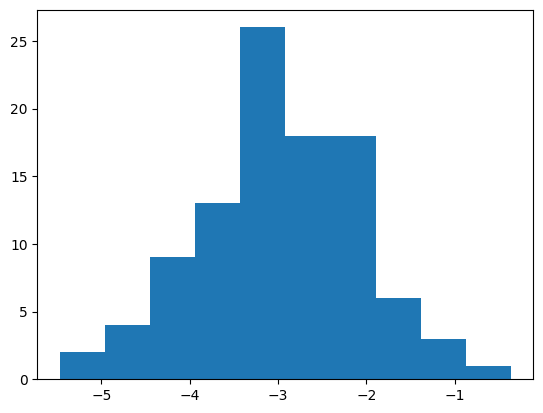

In [14]:
plt.hist(theta_particles_history[...,-1][:,0])